## 04b 90-Day Value of a New Install

**Objective:**
Predict how much IAP revenue a new install will generate during its first
90 days, using only information available by the end of the player's first
7 days.

Before modelling, I first check which players can receive a complete
90-day revenue label. Players without a fully observable 90-day window are
right-censored and should not be used as labelled examples.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.db import get_connection

conn = get_connection()

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

print("Database connected")

Database connected


In [2]:
profile = pd.read_sql_query("""
SELECT
    device_id,
    install_date,
    platform,
    country_tier,
    acquisition_channel
FROM player_profile
""", conn)

profile['install_date'] = pd.to_datetime(
    profile['install_date']
)

player_day = pd.read_sql_query("""
SELECT
    MIN(activity_date) AS min_date,
    MAX(activity_date) AS max_date
FROM player_day
""", conn)

min_date = pd.to_datetime(
    str(player_day.loc[0, 'min_date']),
    format='%Y%m%d'
)

max_date = pd.to_datetime(
    str(player_day.loc[0, 'max_date']),
    format='%Y%m%d'
)

print("Observation window:", min_date.date(), "to", max_date.date())
print("Total players:", len(profile))

Observation window: 2026-01-01 to 2026-04-30
Total players: 80295


In [3]:
latest_eligible_install = max_date - pd.Timedelta(days=89)

print(
    "Latest install date eligible for complete 90-day label:",
    latest_eligible_install.date()
)

profile['full_90d_label'] = (
    profile['install_date'] <= latest_eligible_install
)

eligibility_summary = pd.DataFrame({
    'group': [
        'All players',
        'Complete 90-day label',
        'Right-censored'
    ],
    'players': [
        len(profile),
        profile['full_90d_label'].sum(),
        (~profile['full_90d_label']).sum()
    ]
})

eligibility_summary['share'] = (
    eligibility_summary['players'] / len(profile)
)

eligibility_summary

Latest install date eligible for complete 90-day label: 2026-01-31


,group,players,share
0,All players,80295,1.0000
1,Complete 90-day label,25809,0.3214
2,Right-censored,54486,0.6786


In [4]:
eligible = profile[
    profile['full_90d_label']
].copy()

print("Eligible players:", len(eligible))

print(
    "Eligible install range:",
    eligible['install_date'].min(),
    "to",
    eligible['install_date'].max()
)

eligible.groupby(
    eligible['install_date'].dt.to_period('M')
).size()

Eligible players: 25809
Eligible install range: 2025-05-27 00:00:00 to 2026-01-31 00:00:00


install_date
2025-05     377
2025-06    2215
2025-07    2324
2025-08    2202
2025-09    2166
2025-10    2299
2025-11    2153
2025-12    2264
2026-01    9809
Freq: M, dtype: int64

In [5]:
eligible['full_first_7d_features'] = (
    (eligible['install_date'] >= min_date) &
    (eligible['install_date'] + pd.Timedelta(days=6) <= max_date)
)

model_eligible = eligible[
    eligible['full_first_7d_features']
].copy()

print("90-day label eligible:", len(eligible))
print("Also complete first-7-day features:", len(model_eligible))

print(
    "Final eligible share:",
    round(len(model_eligible) / len(profile), 4)
)

90-day label eligible: 25809
Also complete first-7-day features: 9809
Final eligible share: 0.1222


In [6]:
final_eligibility = pd.DataFrame({
    'metric': [
        'Total players',
        'Complete 90-day outcome',
        'Complete 90-day outcome + first 7-day features',
        'Excluded / censored'
    ],
    'players': [
        len(profile),
        len(eligible),
        len(model_eligible),
        len(profile) - len(model_eligible)
    ]
})

final_eligibility

,metric,players
0,Total players,80295
1,Complete 90-day outcome,25809
2,Complete 90-day outcome + first 7-day features,9809
3,Excluded / censored,70486


In [7]:
activity = pd.read_sql_query("""
SELECT
    device_id,
    activity_date,
    player_level,
    session_count,
    playtime_minutes
FROM player_day
""", conn)

activity['activity_date'] = pd.to_datetime(
    activity['activity_date'].astype(str),
    format='%Y%m%d'
)

purchases = pd.read_sql_query("""
SELECT
    device_id,
    event_ts,
    usd_amount
FROM purchase
""", conn)

purchases['event_ts'] = pd.to_datetime(purchases['event_ts'])
purchases['purchase_date'] = purchases['event_ts'].dt.normalize()

print("Activity rows:", len(activity))
print("Purchase rows:", len(purchases))

Activity rows: 667435
Purchase rows: 15426


In [8]:
base = model_eligible[
    ['device_id', 'install_date',
     'platform', 'country_tier', 'acquisition_channel']
].copy()

act = activity.merge(
    base[['device_id', 'install_date']],
    on='device_id',
    how='inner'
)

act['day_since_install'] = (
    act['activity_date'] - act['install_date']
).dt.days

act_7d = act[
    act['day_since_install'].between(0, 6)
].copy()

activity_features = (
    act_7d.groupby('device_id')
    .agg(
        active_days_7d=('activity_date', 'nunique'),
        sessions_7d=('session_count', 'sum'),
        playtime_7d=('playtime_minutes', 'sum'),
        max_level_7d=('player_level', 'max')
    )
    .reset_index()
)

activity_features.head()

,device_id,active_days_7d,sessions_7d,playtime_7d,max_level_7d
0,100019,5,25,129.2000,6
1,100035,3,11,55.7000,4
2,100045,1,2,14.2000,2
3,100047,6,26,188.3000,6
4,100050,2,6,33.9000,3


In [9]:
pur = purchases.merge(
    base[['device_id', 'install_date']],
    on='device_id',
    how='inner'
)

pur['day_since_install'] = (
    pur['purchase_date'] - pur['install_date']
).dt.days

pur_7d = pur[
    pur['day_since_install'].between(0, 6)
].copy()

purchase_features = (
    pur_7d.groupby('device_id')
    .agg(
        purchase_count_7d=('usd_amount', 'size'),
        revenue_7d=('usd_amount', 'sum')
    )
    .reset_index()
)

purchase_features['payer_7d'] = 1

purchase_features.head()

,device_id,purchase_count_7d,revenue_7d,payer_7d
0,100282,1,4.9900,1
1,100519,1,19.9900,1
2,100764,2,104.9800,1
3,100794,1,9.9900,1
4,100909,1,99.9900,1


In [10]:
pur_90d = pur[
    pur['day_since_install'].between(0, 89)
].copy()

target = (
    pur_90d.groupby('device_id')
    .agg(
        revenue_90d=('usd_amount', 'sum')
    )
    .reset_index()
)

target.head()

,device_id,revenue_90d
0,100047,9.9900
1,100125,1.9900
2,100138,9.9900
3,100211,19.9900
4,100282,14.9700


In [11]:
model_df = (
    base
    .merge(activity_features, on='device_id', how='left')
    .merge(purchase_features, on='device_id', how='left')
    .merge(target, on='device_id', how='left')
)

numeric_fill = [
    'active_days_7d',
    'sessions_7d',
    'playtime_7d',
    'max_level_7d',
    'purchase_count_7d',
    'revenue_7d',
    'payer_7d',
    'revenue_90d'
]

model_df[numeric_fill] = model_df[numeric_fill].fillna(0)

print("Rows:", len(model_df))
print("Duplicate devices:", model_df['device_id'].duplicated().sum())
print("Missing values:")
print(model_df.isna().sum())

model_df.head()

Rows: 9809
Duplicate devices: 0
Missing values:
device_id              0
install_date           0
platform               0
country_tier           0
acquisition_channel    0
active_days_7d         0
sessions_7d            0
playtime_7d            0
max_level_7d           0
purchase_count_7d      0
revenue_7d             0
payer_7d               0
revenue_90d            0
dtype: int64


,device_id,install_date,platform,country_tier,acquisition_channel,active_days_7d,sessions_7d,playtime_7d,max_level_7d,purchase_count_7d,revenue_7d,payer_7d,revenue_90d
0,144689,2026-01-01,Android,2,paid_video,2.0000,5.0000,17.3000,3.0000,0.0000,0.0000,0.0000,0.0000
1,122864,2026-01-01,iOS,4,paid_social,2.0000,7.0000,25.4000,3.0000,0.0000,0.0000,0.0000,0.0000
2,111042,2026-01-01,iOS,1,paid_video,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,128090,2026-01-01,Android,4,organic,2.0000,6.0000,40.1000,3.0000,0.0000,0.0000,0.0000,0.0000
4,143146,2026-01-01,Android,3,organic,2.0000,12.0000,10.0000,3.0000,0.0000,0.0000,0.0000,0.0000


In [12]:
revenue_summary = model_df['revenue_90d'].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
)

zero_revenue_share = (
    model_df['revenue_90d'].eq(0).mean()
)

payer_90d_share = (
    model_df['revenue_90d'].gt(0).mean()
)

print(revenue_summary)

print(
    "\nZero 90-day revenue share:",
    round(zero_revenue_share * 100, 2), "%"
)

print(
    "90-day payer share:",
    round(payer_90d_share * 100, 2), "%"
)

print(
    "Total 90-day revenue:",
    round(model_df['revenue_90d'].sum(), 2)
)

count   9,809.0000
mean        4.6519
std        17.2104
min         0.0000
50%         0.0000
75%         0.0000
90%         9.9900
95%        19.9900
99%        99.9900
max       256.9200
Name: revenue_90d, dtype: float64

Zero 90-day revenue share: 77.77 %
90-day payer share: 22.23 %
Total 90-day revenue: 45630.26


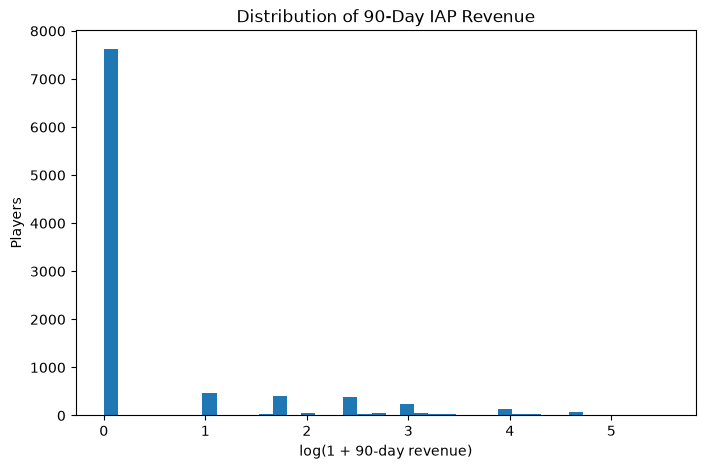

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(
    np.log1p(model_df['revenue_90d']),
    bins=40
)

plt.xlabel("log(1 + 90-day revenue)")
plt.ylabel("Players")
plt.title("Distribution of 90-Day IAP Revenue")

plt.show()

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error
)

from pathlib import Path

OUTPUT_TABLES = Path("../outputs/tables")
OUTPUT_FIGURES = Path("../outputs/figures")

OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)

In [15]:
model_df = model_df.sort_values(
    ['install_date', 'device_id']
).reset_index(drop=True)

model_df['payer_90d'] = (
    model_df['revenue_90d'] > 0
).astype(int)

numeric_features = [
    'active_days_7d',
    'sessions_7d',
    'playtime_7d',
    'max_level_7d',
    'purchase_count_7d',
    'revenue_7d',
    'payer_7d'
]

categorical_features = [
    'platform',
    'country_tier',
    'acquisition_channel'
]

features = numeric_features + categorical_features

print("Players:", len(model_df))
print("90-day payer rate:", round(model_df['payer_90d'].mean(), 4))
print("Install range:", model_df['install_date'].min(), "to", model_df['install_date'].max())

Players: 9809
90-day payer rate: 0.2223
Install range: 2026-01-01 00:00:00 to 2026-01-31 00:00:00


In [16]:
split_date = pd.Timestamp('2026-01-25')

train_df = model_df[
    model_df['install_date'] < split_date
].copy()

test_df = model_df[
    model_df['install_date'] >= split_date
].copy()

print("Train players:", len(train_df))
print("Test players:", len(test_df))

print(
    "Train install range:",
    train_df['install_date'].min(),
    "to",
    train_df['install_date'].max()
)

print(
    "Test install range:",
    test_df['install_date'].min(),
    "to",
    test_df['install_date'].max()
)

print("Train payer rate:", round(train_df['payer_90d'].mean(), 4))
print("Test payer rate:", round(test_df['payer_90d'].mean(), 4))

Train players: 7597
Test players: 2212
Train install range: 2026-01-01 00:00:00 to 2026-01-24 00:00:00
Test install range: 2026-01-25 00:00:00 to 2026-01-31 00:00:00
Train payer rate: 0.2235
Test payer rate: 0.2184


In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numeric_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ]
)

In [18]:
payer_model = Pipeline([
    ('preprocessor', preprocessor),
    (
        'model',
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

payer_model.fit(
    train_df[features],
    train_df['payer_90d']
)

payer_probability = payer_model.predict_proba(
    test_df[features]
)[:, 1]

payer_prediction = (
    payer_probability >= 0.5
).astype(int)

In [19]:
roc_auc = roc_auc_score(
    test_df['payer_90d'],
    payer_probability
)

pr_auc = average_precision_score(
    test_df['payer_90d'],
    payer_probability
)

precision = precision_score(
    test_df['payer_90d'],
    payer_prediction,
    zero_division=0
)

recall = recall_score(
    test_df['payer_90d'],
    payer_prediction,
    zero_division=0
)

f1 = f1_score(
    test_df['payer_90d'],
    payer_prediction,
    zero_division=0
)

print("Stage 1 — 90-Day Payer Classification")
print("--------------------------------------")
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC :", round(pr_auc, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1:", round(f1, 4))

print("\nConfusion Matrix")
print(
    confusion_matrix(
        test_df['payer_90d'],
        payer_prediction
    )
)

print("\nClassification Report")
print(
    classification_report(
        test_df['payer_90d'],
        payer_prediction,
        zero_division=0
    )
)

Stage 1 — 90-Day Payer Classification
--------------------------------------
ROC-AUC: 0.7273
PR-AUC : 0.5471
Precision: 0.8992
Recall: 0.2215
F1: 0.3555

Confusion Matrix
[[1717   12]
 [ 376  107]]

Classification Report
              precision    recall  f1-score   support

           0       0.82      0.99      0.90      1729
           1       0.90      0.22      0.36       483

    accuracy                           0.82      2212
   macro avg       0.86      0.61      0.63      2212
weighted avg       0.84      0.82      0.78      2212



In [20]:
spender_train = train_df[
    train_df['payer_90d'] == 1
].copy()

spender_test = test_df[
    test_df['payer_90d'] == 1
].copy()

spender_train['log_revenue_90d'] = np.log1p(
    spender_train['revenue_90d']
)

print("Training spenders:", len(spender_train))
print("Testing spenders:", len(spender_test))

Training spenders: 1698
Testing spenders: 483


In [21]:
revenue_model = Pipeline([
    ('preprocessor', preprocessor),
    (
        'model',
        Ridge(alpha=1.0)
    )
])

revenue_model.fit(
    spender_train[features],
    spender_train['log_revenue_90d']
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['active_days_7d','sessions_7d','playtime_7d',...,'platform', 'country_tier','acquisition_channel']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thr

In [22]:
spender_log_prediction = revenue_model.predict(
    spender_test[features]
)

spender_revenue_prediction = np.expm1(
    spender_log_prediction
)

spender_revenue_prediction = np.maximum(
    spender_revenue_prediction,
    0
)

spender_mae = mean_absolute_error(
    spender_test['revenue_90d'],
    spender_revenue_prediction
)

spender_rmse = np.sqrt(
    mean_squared_error(
        spender_test['revenue_90d'],
        spender_revenue_prediction
    )
)

print("Stage 2 — Revenue Among Actual Spenders")
print("----------------------------------------")
print("MAE :", round(spender_mae, 4))
print("RMSE:", round(spender_rmse, 4))

Stage 2 — Revenue Among Actual Spenders
----------------------------------------
MAE : 15.3797
RMSE: 30.8254


In [23]:
conditional_log_revenue = revenue_model.predict(
    test_df[features]
)

conditional_revenue = np.expm1(
    conditional_log_revenue
)

conditional_revenue = np.maximum(
    conditional_revenue,
    0
)

expected_revenue = (
    payer_probability * conditional_revenue
)

test_results = test_df[
    [
        'device_id',
        'install_date',
        'revenue_90d',
        'payer_90d'
    ]
].copy()

test_results['payer_probability'] = payer_probability
test_results['conditional_revenue_prediction'] = conditional_revenue
test_results['predicted_90d_value'] = expected_revenue

test_results.head()

,device_id,install_date,revenue_90d,payer_90d,payer_probability,conditional_revenue_prediction,predicted_90d_value
7597,100019,2026-01-25,0.0000,0,0.2769,8.4902,2.3510
7598,100152,2026-01-25,0.0000,0,0.1161,7.9235,0.9196
7599,100198,2026-01-25,0.0000,0,0.1958,7.8662,1.5401
7600,100698,2026-01-25,0.0000,0,0.1637,9.3827,1.5359
7601,100808,2026-01-25,84.9600,1,0.2178,9.4424,2.0561


In [24]:
actual = test_results['revenue_90d']
predicted = test_results['predicted_90d_value']

model_mae = mean_absolute_error(
    actual,
    predicted
)

model_rmse = np.sqrt(
    mean_squared_error(
        actual,
        predicted
    )
)

print("Two-Stage Expected 90-Day Value Model")
print("-------------------------------------")
print("MAE :", round(model_mae, 4))
print("RMSE:", round(model_rmse, 4))

print("\nActual mean revenue:",
      round(actual.mean(), 4))

print("Predicted mean revenue:",
      round(predicted.mean(), 4))

print("Actual total revenue:",
      round(actual.sum(), 2))

print("Predicted total revenue:",
      round(predicted.sum(), 2))

Two-Stage Expected 90-Day Value Model
-------------------------------------
MAE : 4.9583
RMSE: 15.4469

Actual mean revenue: 4.5149
Predicted mean revenue: 2.8402
Actual total revenue: 9986.87
Predicted total revenue: 6282.63


In [25]:
baseline_value = train_df[
    'revenue_90d'
].mean()

baseline_prediction = np.full(
    len(test_df),
    baseline_value
)

baseline_mae = mean_absolute_error(
    actual,
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        actual,
        baseline_prediction
    )
)

comparison = pd.DataFrame({
    'model': [
        'Mean revenue baseline',
        'Two-stage model'
    ],
    'MAE': [
        baseline_mae,
        model_mae
    ],
    'RMSE': [
        baseline_rmse,
        model_rmse
    ]
})

comparison

,model,MAE,RMSE
0,Mean revenue baseline,7.4120,16.2867
1,Two-stage model,4.9583,15.4469


In [26]:
ranking = test_results.sort_values(
    'predicted_90d_value',
    ascending=False
).reset_index(drop=True)

ranking['decile'] = pd.qcut(
    ranking.index,
    10,
    labels=False
) + 1

decile_summary = (
    ranking.groupby('decile')
    .agg(
        players=('device_id', 'size'),
        actual_revenue=('revenue_90d', 'sum'),
        avg_actual_revenue=('revenue_90d', 'mean'),
        avg_predicted_value=('predicted_90d_value', 'mean'),
        payer_rate=('payer_90d', 'mean')
    )
    .reset_index()
)

total_test_revenue = decile_summary[
    'actual_revenue'
].sum()

decile_summary['revenue_share'] = (
    decile_summary['actual_revenue']
    / total_test_revenue
)

decile_summary

,decile,players,actual_revenue,avg_actual_revenue,avg_predicted_value,payer_rate,revenue_share
0,1,222,"4,212.2400",18.9741,15.0163,0.6622,0.4218
1,2,221,"1,016.1200",4.5978,2.6800,0.3077,0.1017
2,3,221,"1,209.2300",5.4716,2.2100,0.2579,0.1211
3,4,221,867.3800,3.9248,1.8581,0.1991,0.0869
4,5,221,737.5100,3.3371,1.5667,0.1538,0.0738
5,6,221,560.5200,2.5363,1.3873,0.1719,0.0561
6,7,221,457.6200,2.0707,1.1909,0.1357,0.0458
7,8,221,408.7600,1.8496,0.9906,0.0950,0.0409
8,9,221,259.7400,1.1753,0.8345,0.0995,0.0260
9,10,222,257.7500,1.1610,0.6231,0.0991,0.0258


In [27]:
top_10 = ranking.head(
    int(np.ceil(len(ranking) * 0.10))
)

top10_revenue_capture = (
    top_10['revenue_90d'].sum()
    / ranking['revenue_90d'].sum()
)

print(
    "Actual revenue captured by top 10% predicted players:",
    round(top10_revenue_capture * 100, 2),
    "%"
)

print(
    "Top 10% actual payer rate:",
    round(top_10['payer_90d'].mean() * 100, 2),
    "%"
)

Actual revenue captured by top 10% predicted players: 42.18 %
Top 10% actual payer rate: 66.22 %


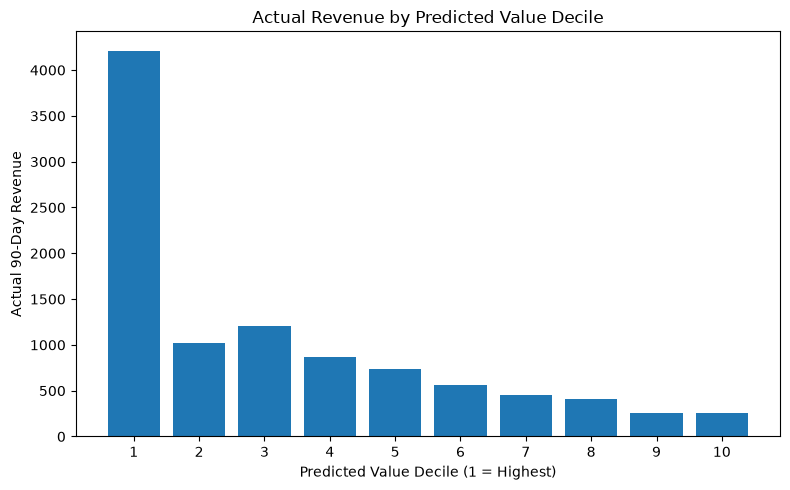

In [28]:
plt.figure(figsize=(8, 5))

plt.bar(
    decile_summary['decile'].astype(str),
    decile_summary['actual_revenue']
)

plt.xlabel("Predicted Value Decile (1 = Highest)")
plt.ylabel("Actual 90-Day Revenue")
plt.title("Actual Revenue by Predicted Value Decile")

plt.tight_layout()

plt.savefig(
    OUTPUT_FIGURES / "04b_value_deciles.png",
    dpi=200,
    bbox_inches='tight'
)

plt.show()

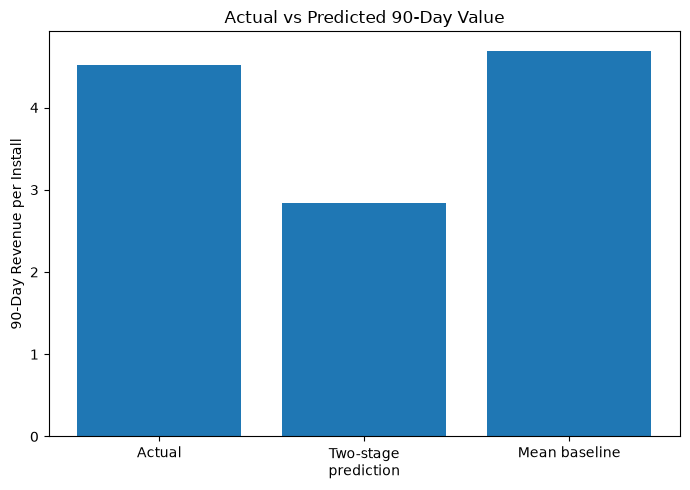

In [29]:
plt.figure(figsize=(7, 5))

labels = [
    'Actual',
    'Two-stage\nprediction',
    'Mean baseline'
]

values = [
    actual.mean(),
    predicted.mean(),
    baseline_value
]

plt.bar(labels, values)

plt.ylabel("90-Day Revenue per Install")
plt.title("Actual vs Predicted 90-Day Value")

plt.tight_layout()

plt.savefig(
    OUTPUT_FIGURES / "04b_actual_vs_predicted.png",
    dpi=200,
    bbox_inches='tight'
)

plt.show()

In [30]:
eligibility_summary.to_csv(
    OUTPUT_TABLES / "04b_eligibility_summary.csv",
    index=False
)

final_eligibility.to_csv(
    OUTPUT_TABLES / "04b_final_eligibility.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_TABLES / "04b_model_comparison.csv",
    index=False
)

decile_summary.to_csv(
    OUTPUT_TABLES / "04b_value_deciles.csv",
    index=False
)

test_results.to_csv(
    OUTPUT_TABLES / "04b_test_predictions.csv",
    index=False
)

print("4b summary saved successfully.")

4b summary saved successfully.


In [31]:
summary = pd.DataFrame({
    'metric': [
        'Eligible players',
        'Eligible share of total players',
        '90-day payer rate',
        'Stage 1 ROC-AUC',
        'Stage 1 PR-AUC',
        'Two-stage MAE',
        'Two-stage RMSE',
        'Baseline MAE',
        'Baseline RMSE',
        'Top 10% predicted revenue capture'
    ],
    'value': [
        len(model_df),
        len(model_df) / len(profile),
        model_df['payer_90d'].mean(),
        roc_auc,
        pr_auc,
        model_mae,
        model_rmse,
        baseline_mae,
        baseline_rmse,
        top10_revenue_capture
    ]
})

summary

,metric,value
0,Eligible players,"9,809.0000"
1,Eligible share of total players,0.1222
2,90-day payer rate,0.2223
3,Stage 1 ROC-AUC,0.7273
4,Stage 1 PR-AUC,0.5471
5,Two-stage MAE,4.9583
6,Two-stage RMSE,15.4469
7,Baseline MAE,7.4120
8,Baseline RMSE,16.2867
9,Top 10% predicted revenue capture,0.4218


## Final Findings

- Only **9,809 players (12.22% of all players)** have both a fully observable 90-day revenue window and complete first-7-day feature availability. Results therefore apply to this restricted, uncensored population.

- The 90-day payer rate among eligible players is **22.23%**, and the revenue distribution is highly skewed, with **77.77% of players generating zero IAP revenue** during their first 90 days.

- The Stage-1 payer model achieves a **ROC-AUC of 0.7273** and **PR-AUC of 0.5471**, indicating useful separation between future payers and non-payers.

- The two-stage expected-value model achieves **MAE = 4.9583** and **RMSE = 15.4469**, outperforming the mean-revenue baseline (**MAE = 7.4120, RMSE = 16.2867**).

- The highest predicted-value 10% of test players account for **42.18% of actual 90-day revenue**, showing that the model provides useful value ranking for prioritization.

- However, the model underpredicts aggregate value: mean predicted 90-day revenue is **$2.84 per install** versus an actual **$4.51**, so the predictions should not be treated as fully calibrated revenue forecasts.

- Because most later installs do not yet have a complete 90-day outcome window, additional observation time and out-of-time validation are required before using the model for production decisions.